In [47]:
import torch

inputs = torch.tensor(
    [
        [0.43, 0.15, 0.89],  # Your     (x^1)
        [0.55, 0.87, 0.66],  # journey  (x^2)
        [0.57, 0.85, 0.64],  # starts   (x^3)
        [0.22, 0.58, 0.33],  # with     (x^4)
        [0.77, 0.25, 0.10],  # one      (x^5)
        [0.05, 0.80, 0.55],  # step     (x^6)
    ]
)
query = inputs[1]  # The second input token serves as the query.

attn_scores_2 = torch.empty(inputs.shape[0])
for i, x_i in enumerate(inputs):
    attn_scores_2[i] = torch.dot(x_i, query)
print(attn_scores_2)

tensor([0.9544, 1.4950, 1.4754, 0.8434, 0.7070, 1.0865])


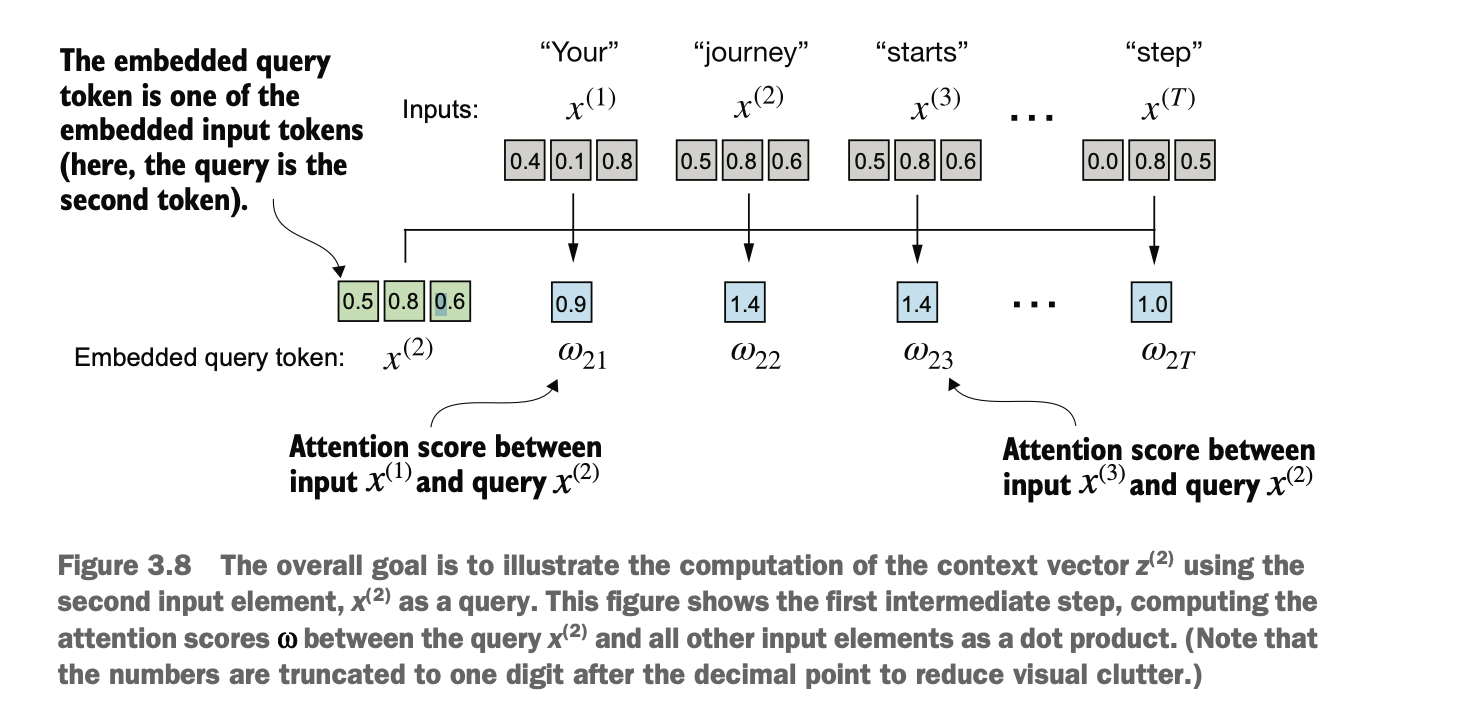


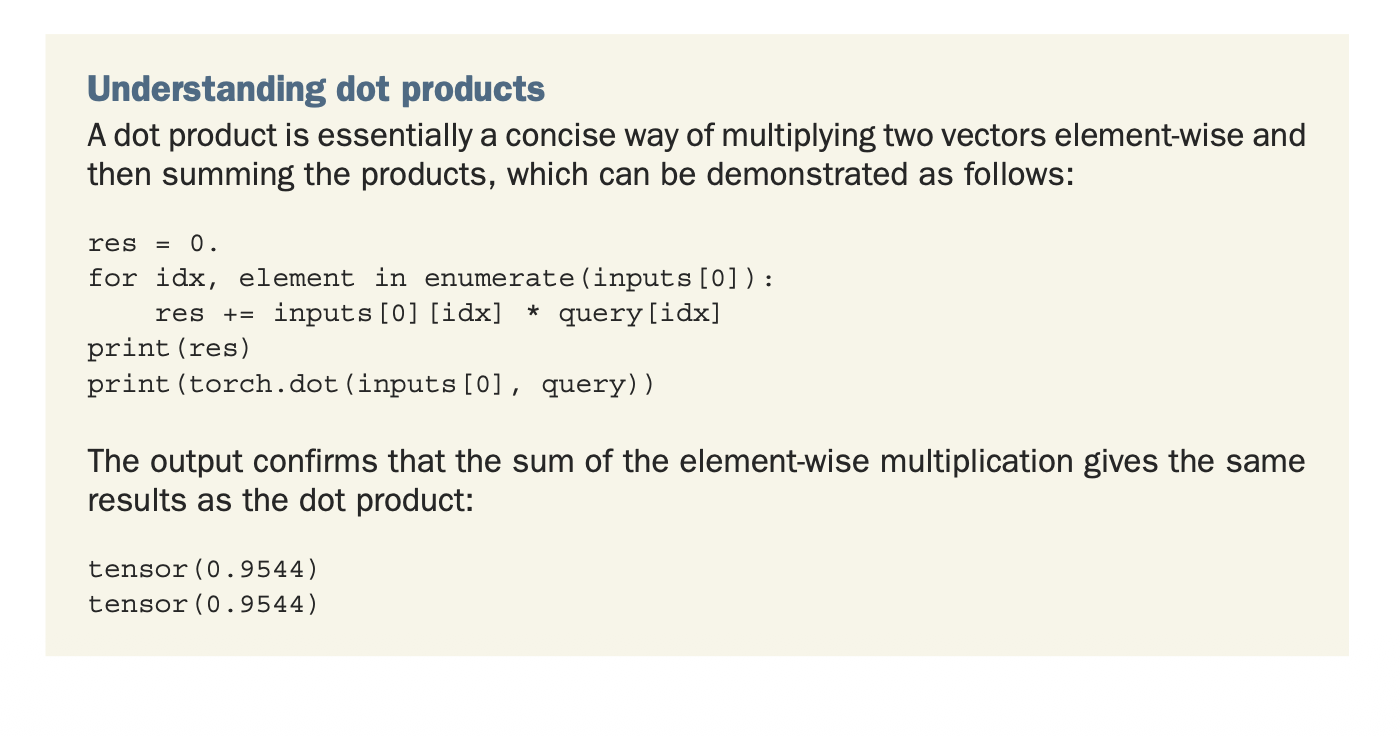


In [48]:
res = 0.0
for idx, element in enumerate(inputs[0]):
    res += inputs[0][idx] * query[idx]
print(res)
print(torch.dot(inputs[0], query))

tensor(0.9544)
tensor(0.9544)


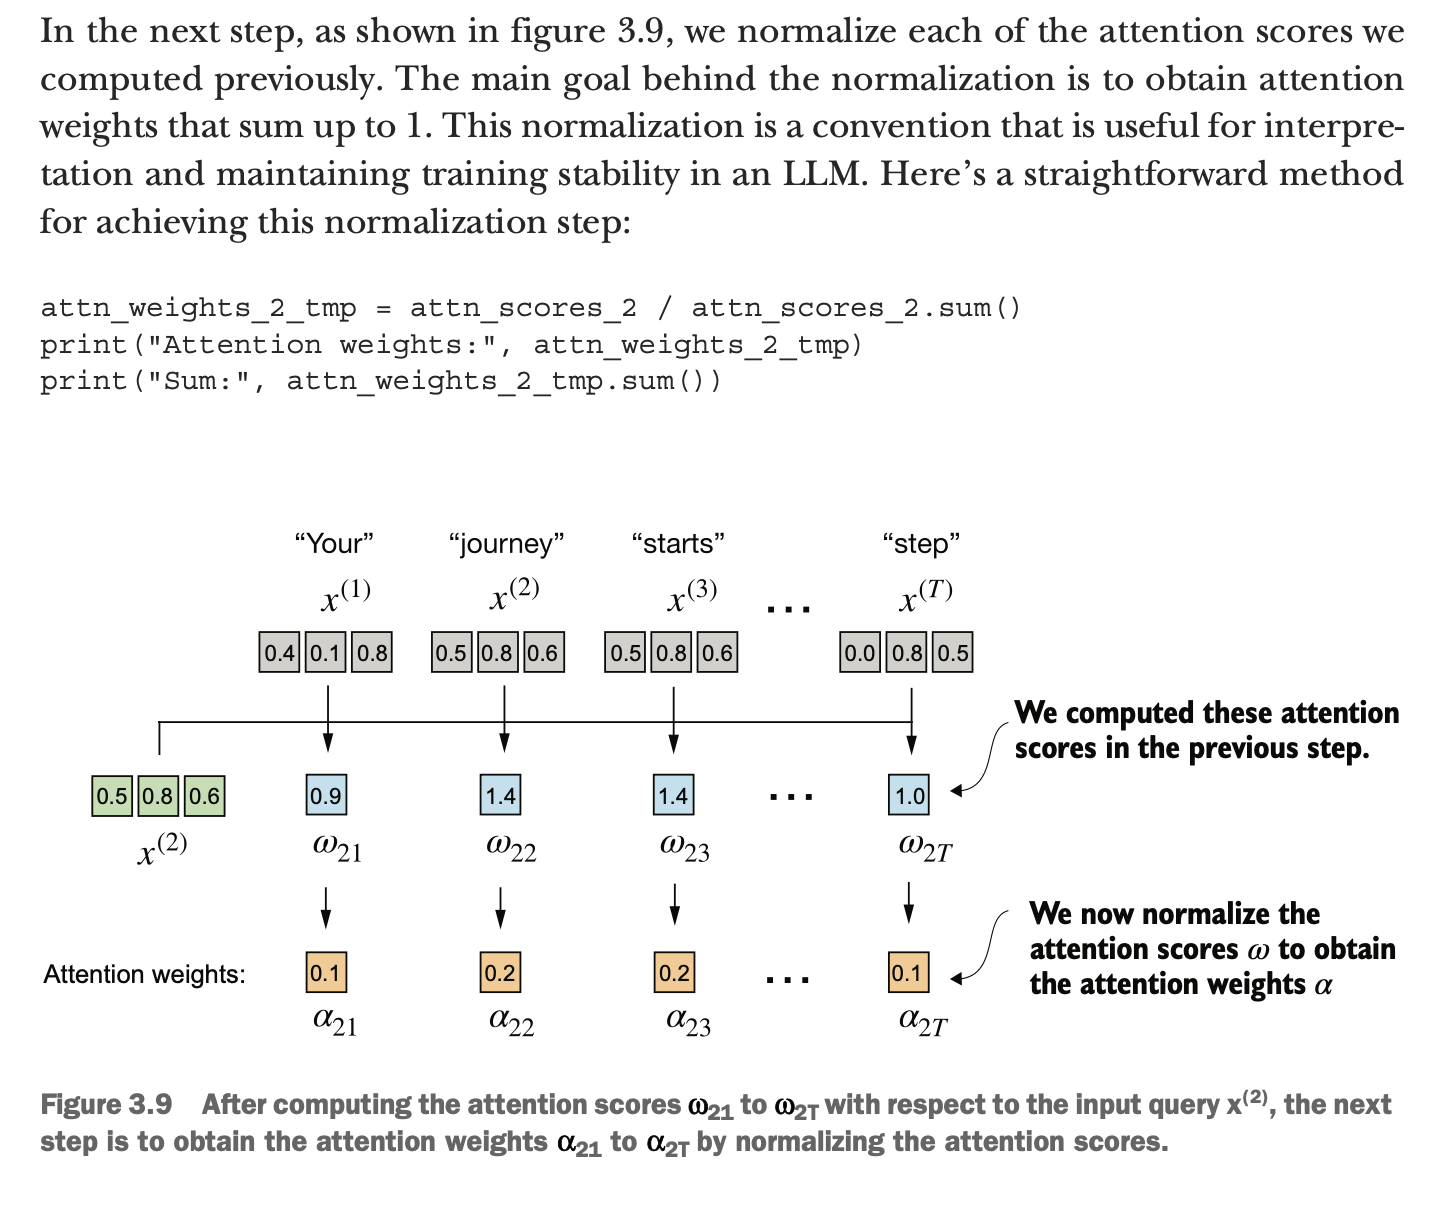


In [49]:
attn_weights_2_tmp = attn_scores_2 / attn_scores_2.sum()
print("Attention weights:", attn_weights_2_tmp)
print("Sum:", attn_weights_2_tmp.sum())

Attention weights: tensor([0.1455, 0.2278, 0.2249, 0.1285, 0.1077, 0.1656])
Sum: tensor(1.0000)


In [50]:
# In practice, it’s more common and advisable to use the softmax function for normal-
# ization. This approach is better at managing extreme values and offers more favorable
# gradient properties during training. The following is a basic implementation of the
# softmax function for normalizing the attention scores:


def softmax_naive(x):
    return torch.exp(x) / torch.exp(x).sum(dim=0)


attn_weights_2_naive = softmax_naive(attn_scores_2)
print("Attention weights:", attn_weights_2_naive)
print("Sum:", attn_weights_2_naive.sum())

Attention weights: tensor([0.1385, 0.2379, 0.2333, 0.1240, 0.1082, 0.1581])
Sum: tensor(1.)


In [51]:
#   Naive softmax implementation (softmax_naive) may encounter
# numerical instability problems, such as overflow and underflow, when dealing with
# large or small input values. Therefore, in practice, it’s advisable to use the PyTorch
# implementation of softmax, which has been extensively optimized for performance:

attn_weights_2 = torch.softmax(attn_scores_2, dim=0)
print("Attention weights:", attn_weights_2)
print("Sum:", attn_weights_2.sum())

Attention weights: tensor([0.1385, 0.2379, 0.2333, 0.1240, 0.1082, 0.1581])
Sum: tensor(1.)


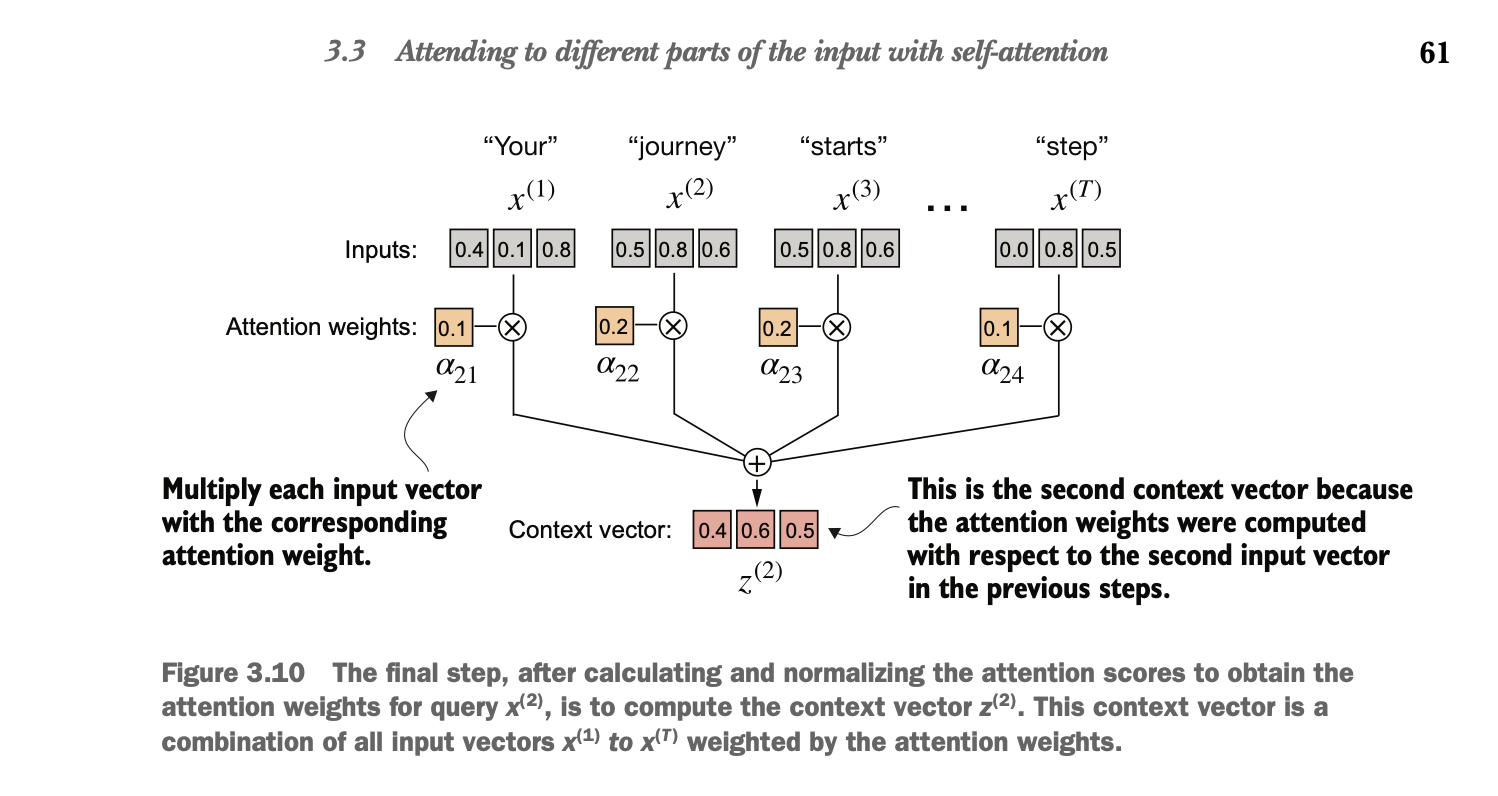


In [52]:
query = inputs[1]
context_vec_2 = torch.zeros(query.shape)
for i, x_i in enumerate(inputs):
    context_vec_2 += attn_weights_2[i] * x_i
print(context_vec_2)

tensor([0.4419, 0.6515, 0.5683])


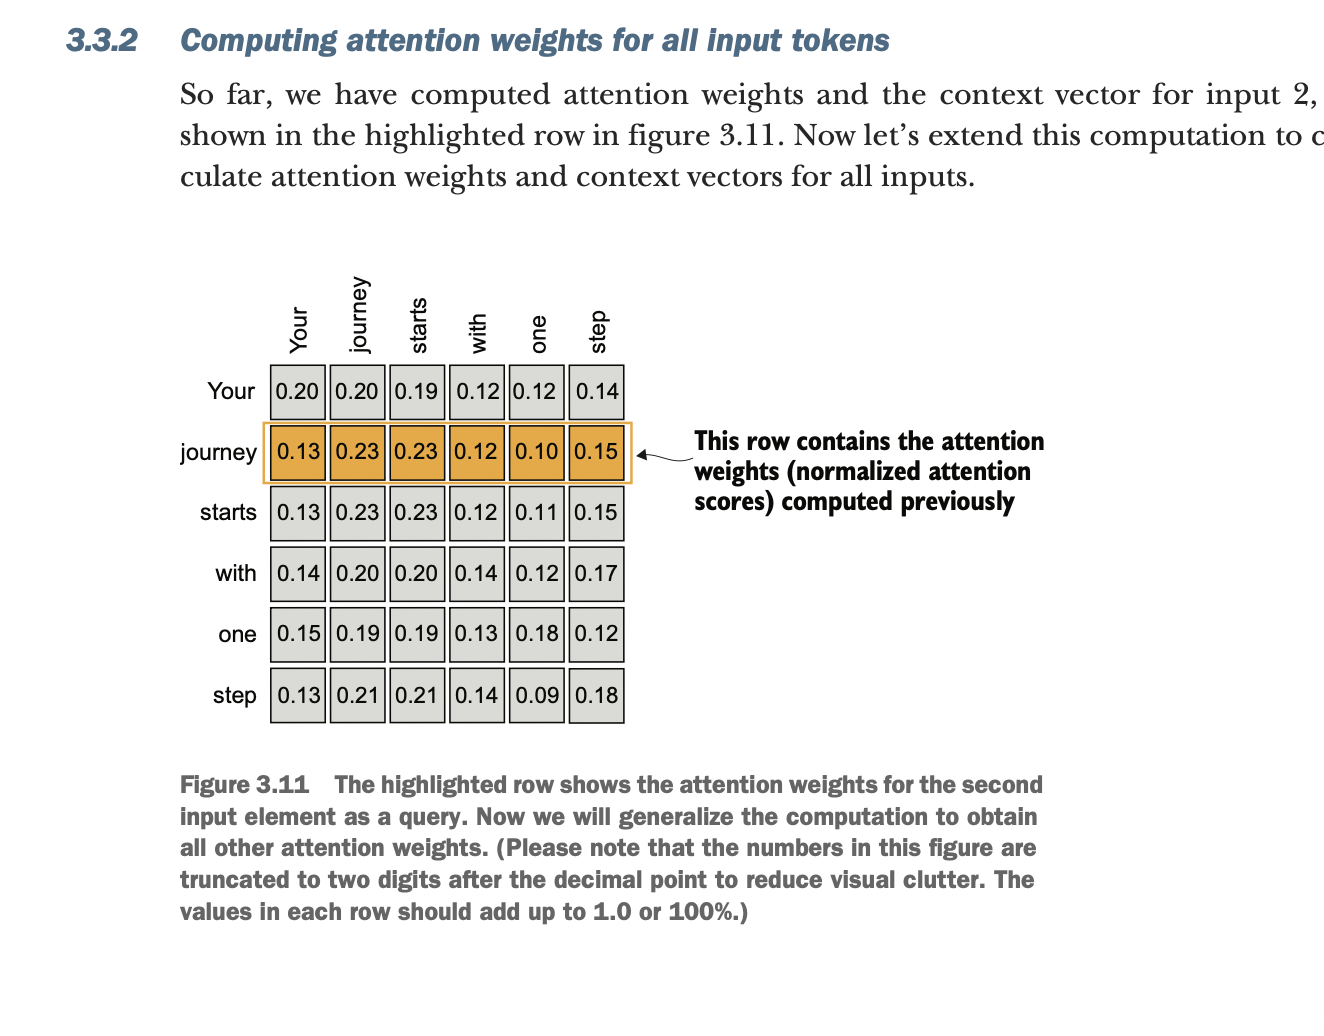


In [53]:
attn_scores = torch.empty(6, 6)

for i, x_i in enumerate(inputs):
    for j, x_j in enumerate(inputs):
        attn_scores[i, j] = torch.dot(x_i, x_j)
print(attn_scores)

tensor([[0.9995, 0.9544, 0.9422, 0.4753, 0.4576, 0.6310],
        [0.9544, 1.4950, 1.4754, 0.8434, 0.7070, 1.0865],
        [0.9422, 1.4754, 1.4570, 0.8296, 0.7154, 1.0605],
        [0.4753, 0.8434, 0.8296, 0.4937, 0.3474, 0.6565],
        [0.4576, 0.7070, 0.7154, 0.3474, 0.6654, 0.2935],
        [0.6310, 1.0865, 1.0605, 0.6565, 0.2935, 0.9450]])


In [54]:
# for loops are slow and I should use matrix multiplication:

attn_scores = inputs @ inputs.T
print(attn_scores)

tensor([[0.9995, 0.9544, 0.9422, 0.4753, 0.4576, 0.6310],
        [0.9544, 1.4950, 1.4754, 0.8434, 0.7070, 1.0865],
        [0.9422, 1.4754, 1.4570, 0.8296, 0.7154, 1.0605],
        [0.4753, 0.8434, 0.8296, 0.4937, 0.3474, 0.6565],
        [0.4576, 0.7070, 0.7154, 0.3474, 0.6654, 0.2935],
        [0.6310, 1.0865, 1.0605, 0.6565, 0.2935, 0.9450]])


![Screenshot 2026-07-25 at 13.57.33.png](<attachment:Screenshot 2026-07-25 at 13.57.33.png>)

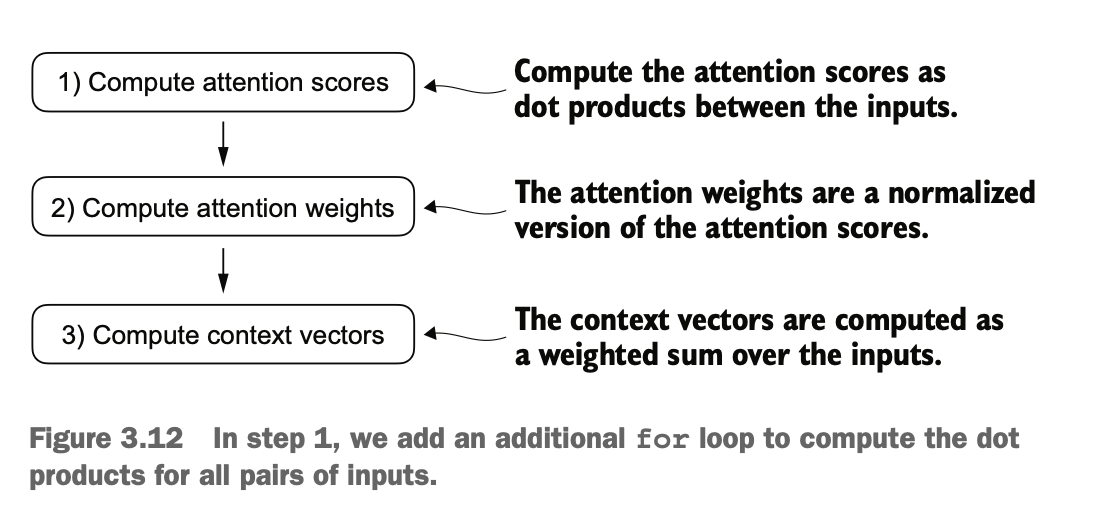

In [55]:
attn_weights = torch.softmax(attn_scores, dim=-1)
print(attn_weights)

# We can verify that the rows indeed all sum to 1:
row_2_sum = sum([0.1385, 0.2379, 0.2333, 0.1240, 0.1082, 0.1581])
print("Row 2 sum:", row_2_sum)
print("All row sums:", attn_weights.sum(dim=-1))

tensor([[0.2098, 0.2006, 0.1981, 0.1242, 0.1220, 0.1452],
        [0.1385, 0.2379, 0.2333, 0.1240, 0.1082, 0.1581],
        [0.1390, 0.2369, 0.2326, 0.1242, 0.1108, 0.1565],
        [0.1435, 0.2074, 0.2046, 0.1462, 0.1263, 0.1720],
        [0.1526, 0.1958, 0.1975, 0.1367, 0.1879, 0.1295],
        [0.1385, 0.2184, 0.2128, 0.1420, 0.0988, 0.1896]])
Row 2 sum: 1.0
All row sums: tensor([1.0000, 1.0000, 1.0000, 1.0000, 1.0000, 1.0000])


In [56]:
# In the third and final step of figure 3.12,
# we use these attention weights to compute all
# context vectors via matrix multiplication:

all_context_vecs = attn_weights @ inputs
print(all_context_vecs)

# We can double-check that the code is correct by
# comparing the second row with the
# context vector z(2) that we computed in section 3.3.1:
print("Previous 2nd context vector:", context_vec_2)

tensor([[0.4421, 0.5931, 0.5790],
        [0.4419, 0.6515, 0.5683],
        [0.4431, 0.6496, 0.5671],
        [0.4304, 0.6298, 0.5510],
        [0.4671, 0.5910, 0.5266],
        [0.4177, 0.6503, 0.5645]])
Previous 2nd context vector: tensor([0.4419, 0.6515, 0.5683])


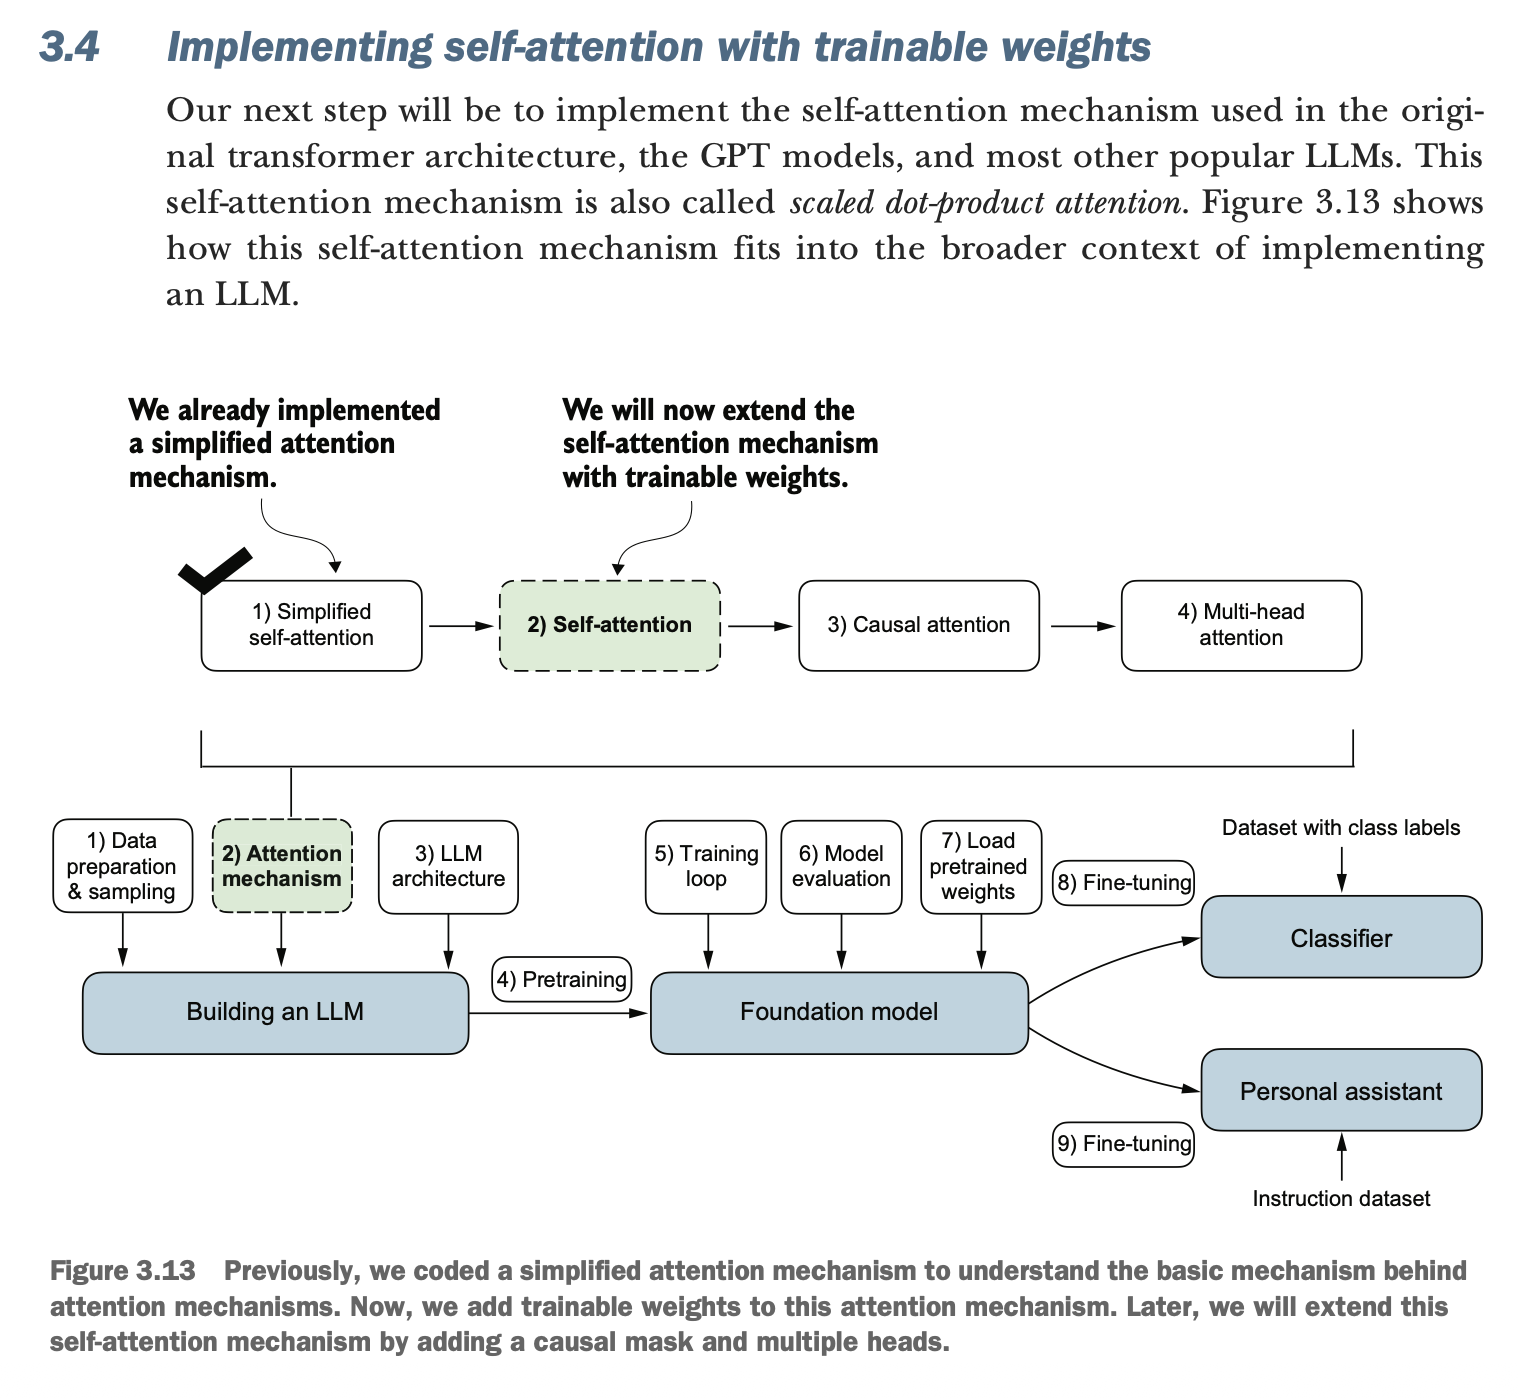


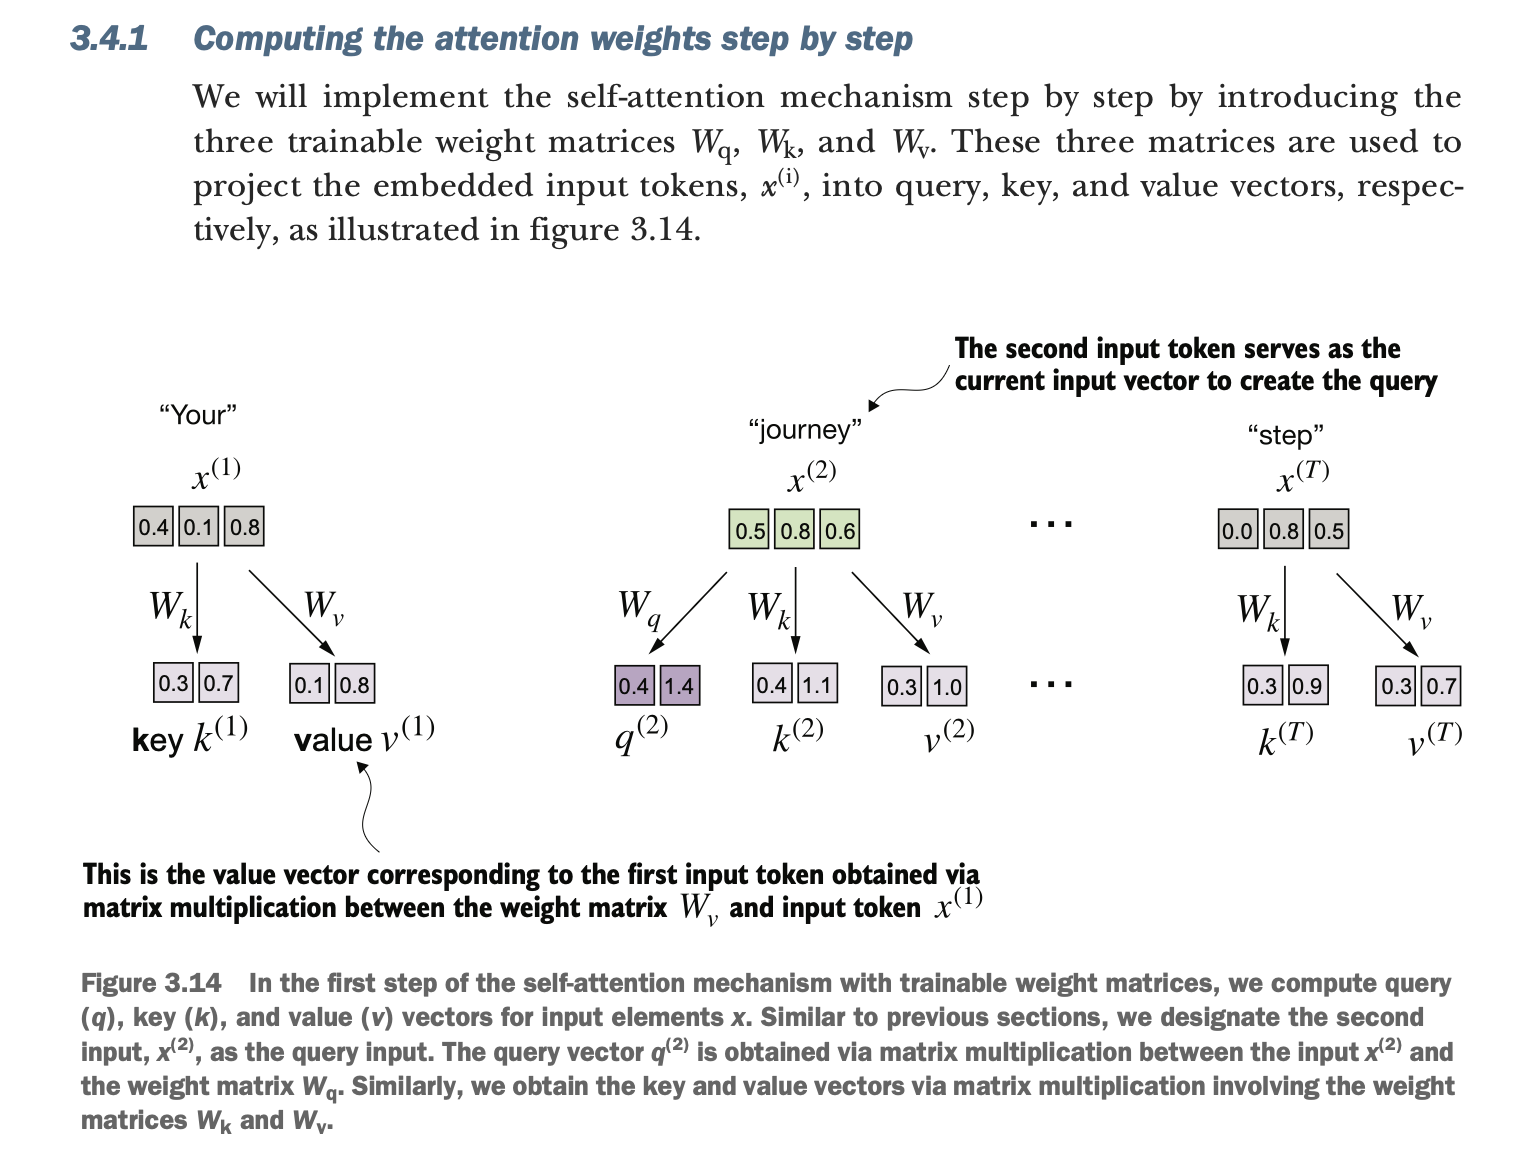


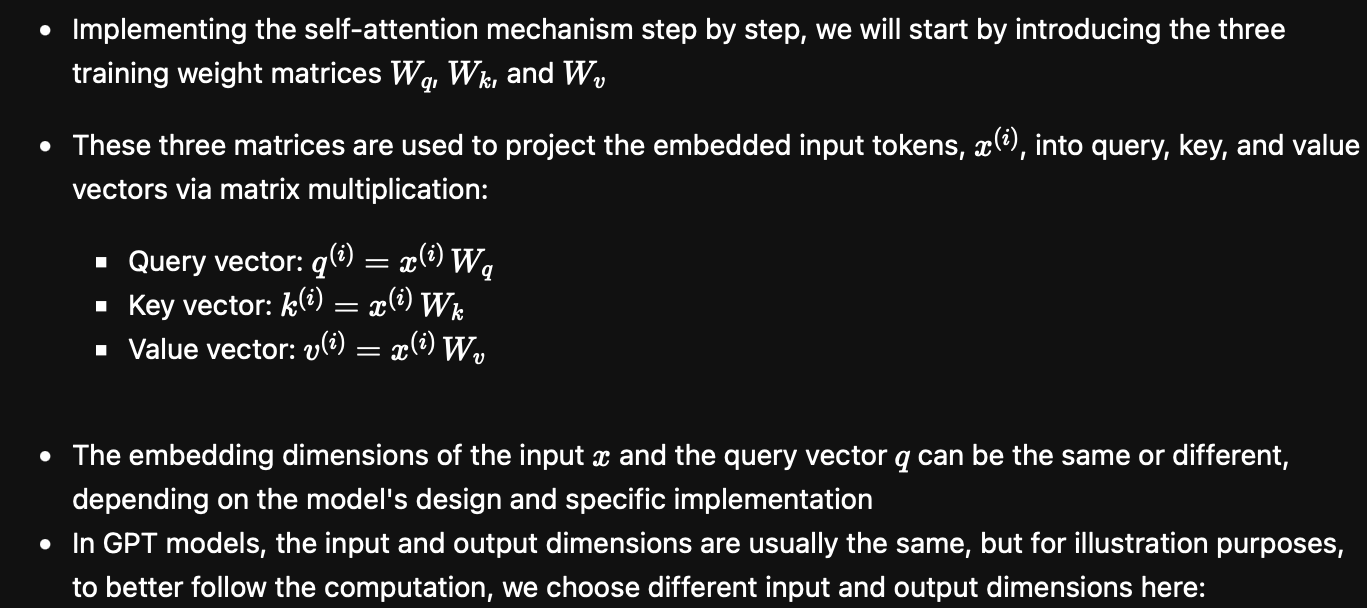


In [ ]:
x_2 = inputs[1]  # second input element
d_in = inputs.shape[1]  # the input embedding size, d=3
d_out = 2  # the output embedding size, d=2



> - Below, we initialize the three weight matrices; note that we are setting requires_grad=False to reduce clutter in the outputs for illustration purposes, but if we were to use the weight matrices for model training, we would set requires_grad=True to update these matrices during model training


In [ ]:
# Next, we initialize the three weight matrices
# Wq, Wk, and Wv shown in figure 3.14:

torch.manual_seed(123)
W_query = torch.nn.Parameter(torch.rand(d_in, d_out), requires_grad=False)
W_key = torch.nn.Parameter(torch.rand(d_in, d_out), requires_grad=False)
W_value = torch.nn.Parameter(torch.rand(d_in, d_out), requires_grad=False)

print("Query :\n ", W_query, " \nKey: \n", W_key, "\nValue:\n ", W_value)

## OUTPUT:

> - Query :
>   Parameter containing:
>   tensor([[0.2961, 0.5166],

        [0.2517, 0.6886],
        [0.0740, 0.8665]])

> - Key:
>   Parameter containing:
>   tensor([[0.1366, 0.1025],

        [0.1841, 0.7264],
        [0.3153, 0.6871]])

> - Value:
>   Parameter containing:
>   tensor([[0.0756, 0.1966],

        [0.3164, 0.4017],
        [0.1186, 0.8274]])


> - Next we compute the query, key, and value vectors:


In [61]:
query_2 = x_2 @ W_query  # _2 because it's with respect to the 2nd input element
key_2 = x_2 @ W_key
value_2 = x_2 @ W_value

print(query_2)
print(key_2)

tensor([0.4306, 1.4551])
tensor([0.4433, 1.1419])


> - As we can see below, we successfully projected the 6 input tokens from a 3D onto a 2D embedding space:


In [60]:
keys = inputs @ W_key
values = inputs @ W_value

print("keys.shape:", keys.shape)
print("values.shape:", values.shape)

keys.shape: torch.Size([6, 2])
values.shape: torch.Size([6, 2])


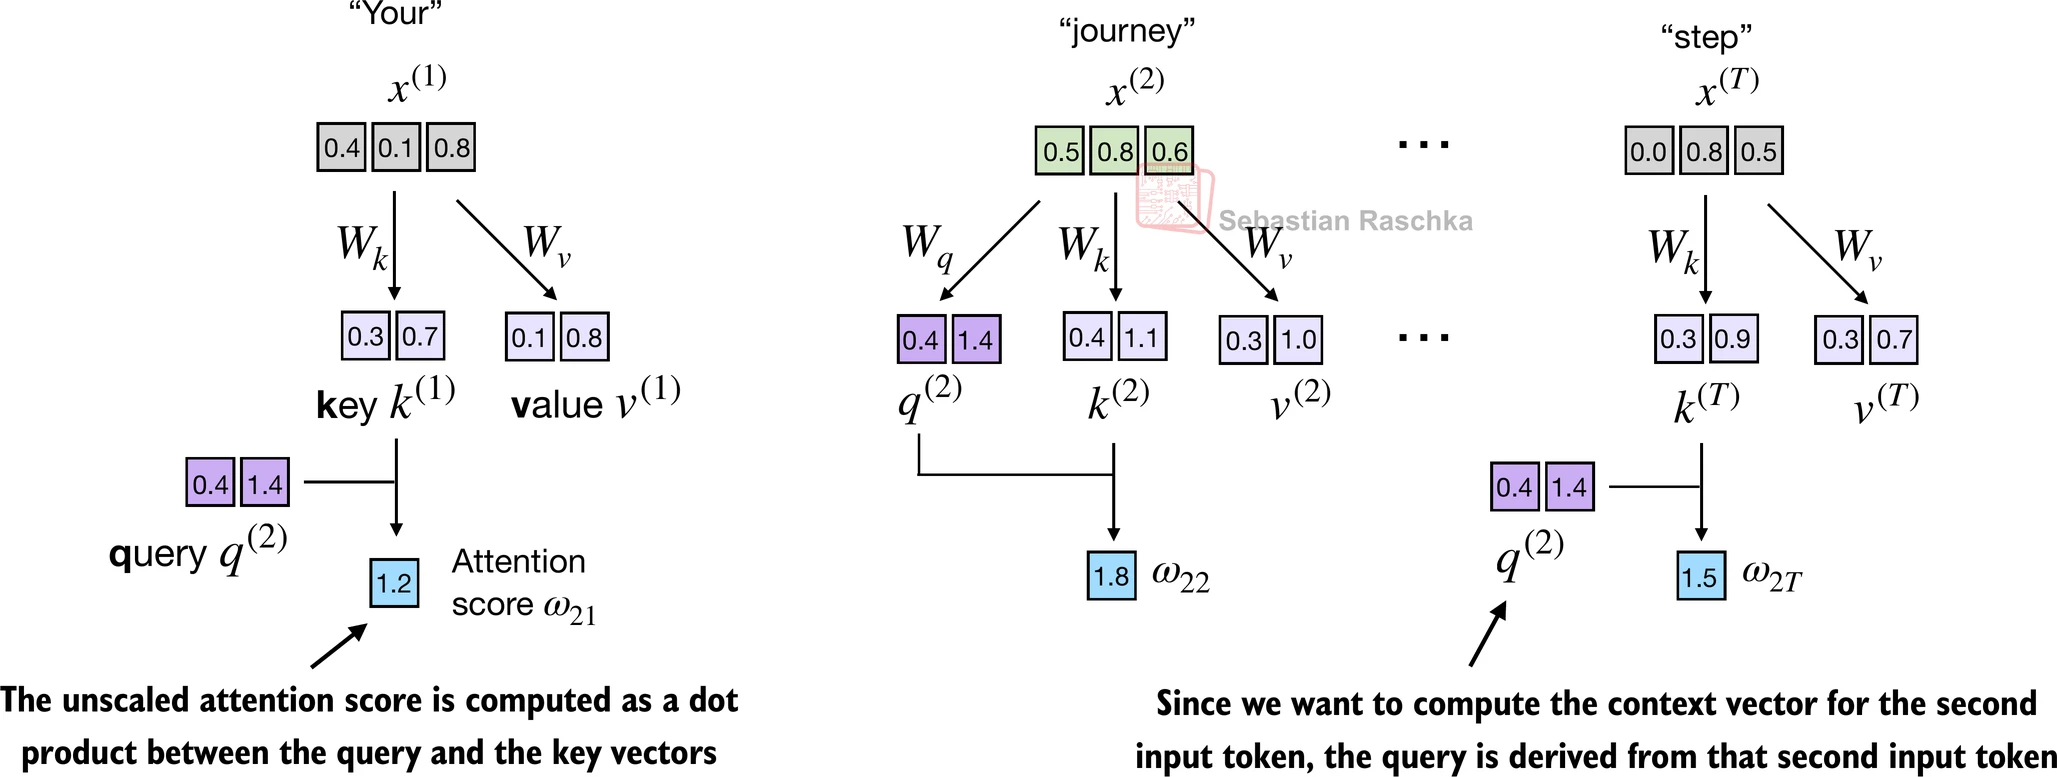


> - In the next step, step 2, we compute the unnormalized attention scores by computing the dot product between the query and each key vector:


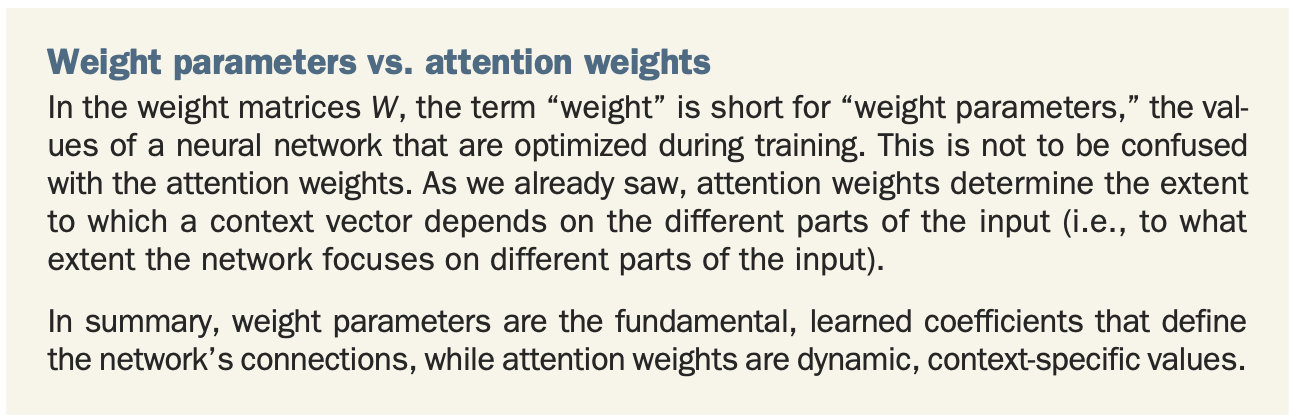


In [71]:
# We can obtain all keys and values via matrix multiplication

keys = inputs @ W_key
values = inputs @ W_value
print("key shape : ", keys.shape)
print("values shape : ", values.shape)

key shape :  torch.Size([6, 2])
values shape :  torch.Size([6, 2])


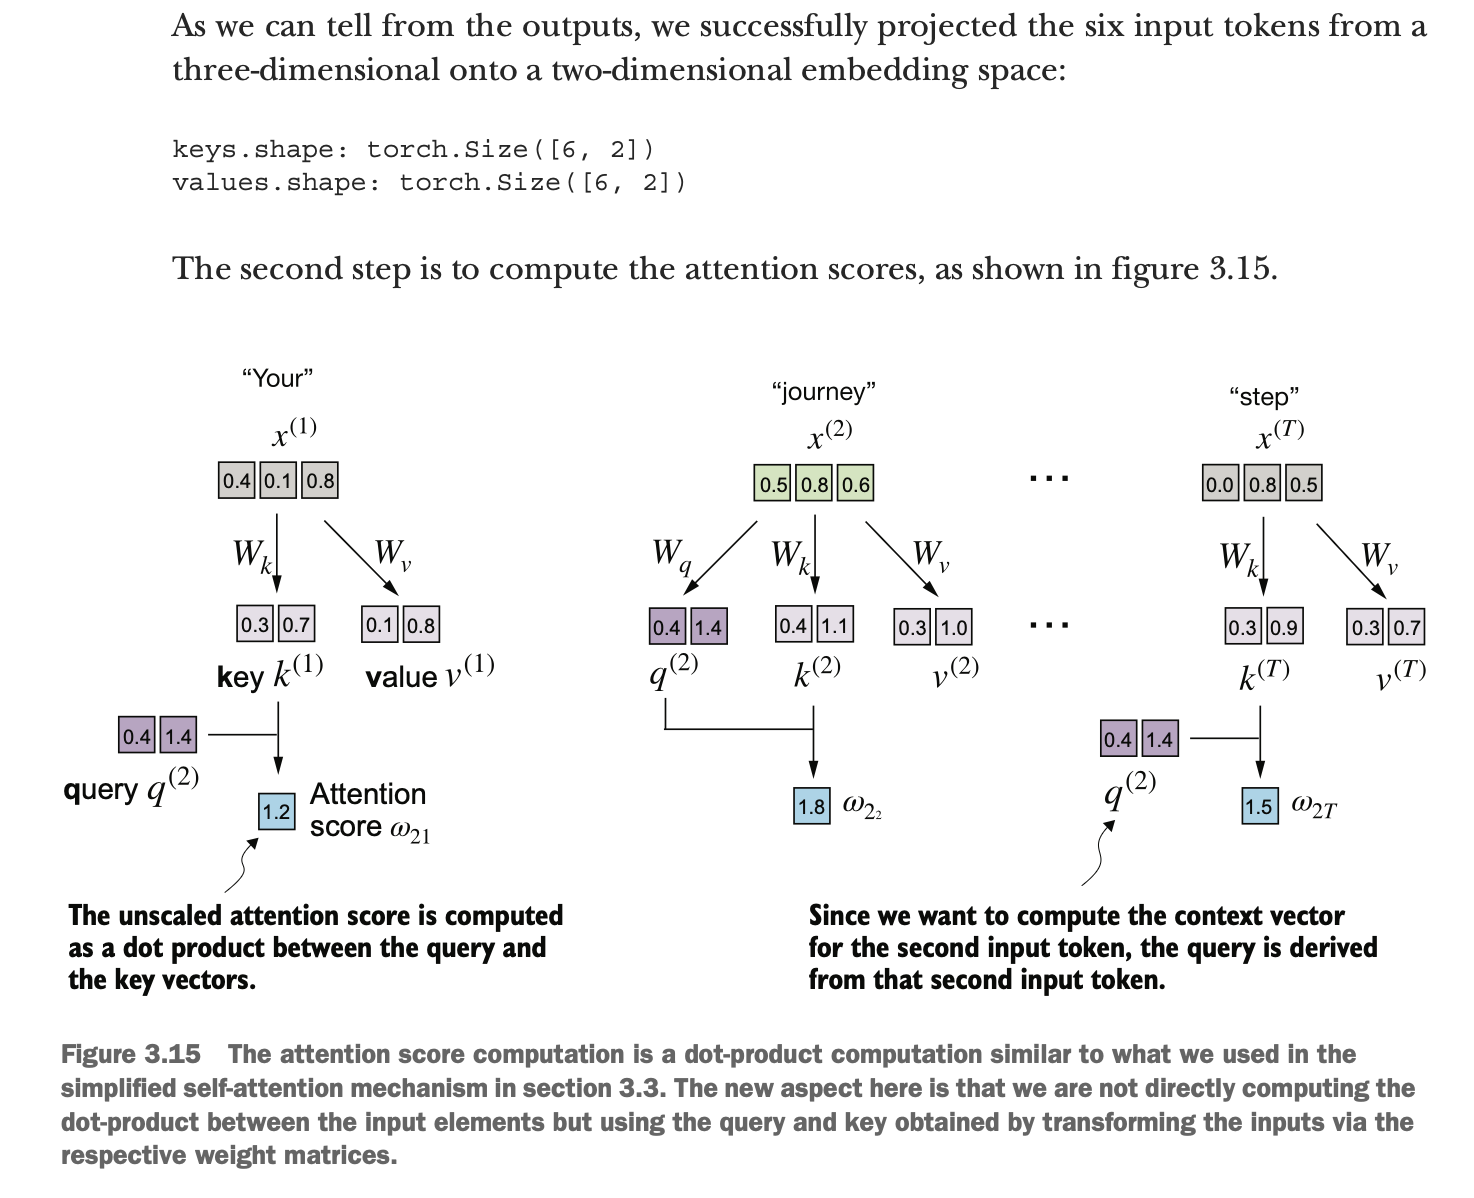


In [74]:
# First, let’s compute the (unnormalized ) attention score ω22:

keys_2 = keys[1]
attn_scores_22 = query_2.dot(keys_2)
print(attn_scores_22)

# Again, we can generalize this computation to all attention scores via matrix
# multiplication :

attn_scores_2 = query_2 @ keys.T
print("\nAll attention scores for given query :\n ", attn_scores_2)

tensor(1.8524)

All attention scores for given query :
  tensor([1.2705, 1.8524, 1.8111, 1.0795, 0.5577, 1.5440])


> - Now, we want to go from the attention scores to the attention weights, as illustrated in figure 3.16.
> - We compute the attention weights by scaling the attention scores and using the softmax function.
> - However, now we scale the attention scores by dividing them by the square root
>   of the embedding dimension of the keys
> - (taking the square root is mathematically the same as exponentiating by 0.5):


In [75]:
d_k = keys.shape[-1]
attn_weights_2 = torch.softmax(attn_scores_2 / d_k**0.5, dim=-1)
print(attn_weights_2)

tensor([0.1500, 0.2264, 0.2199, 0.1311, 0.0906, 0.1820])


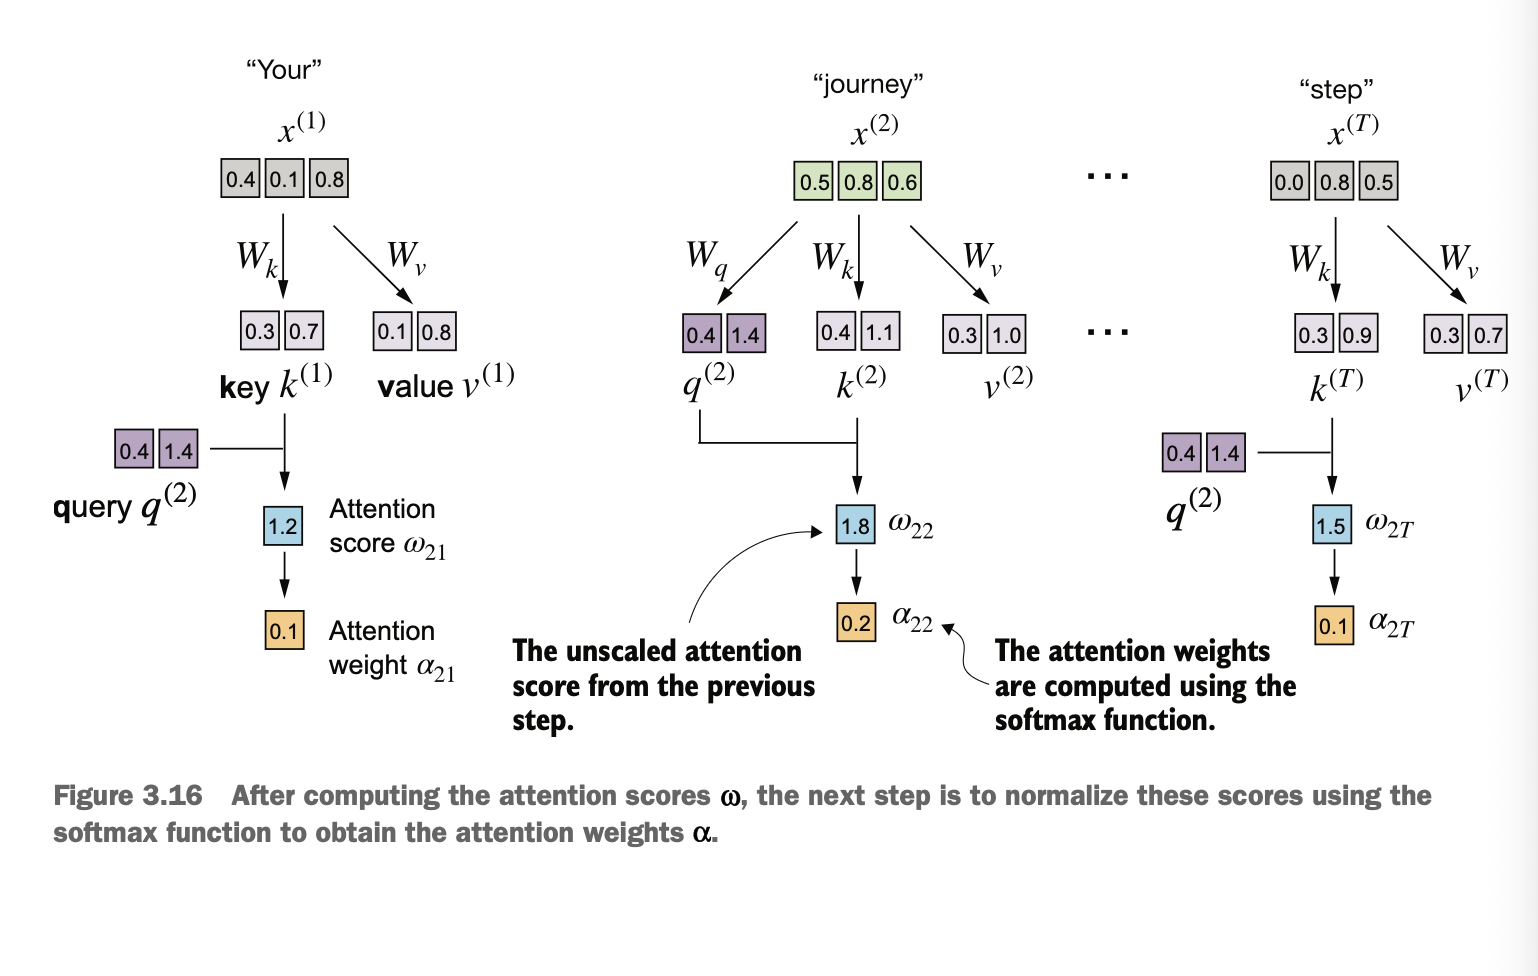


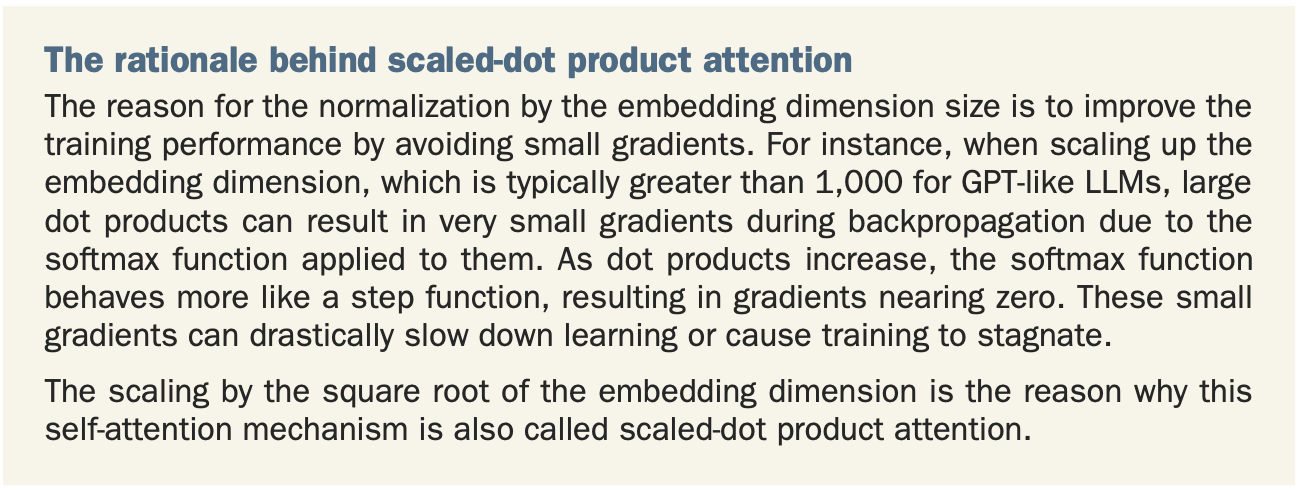


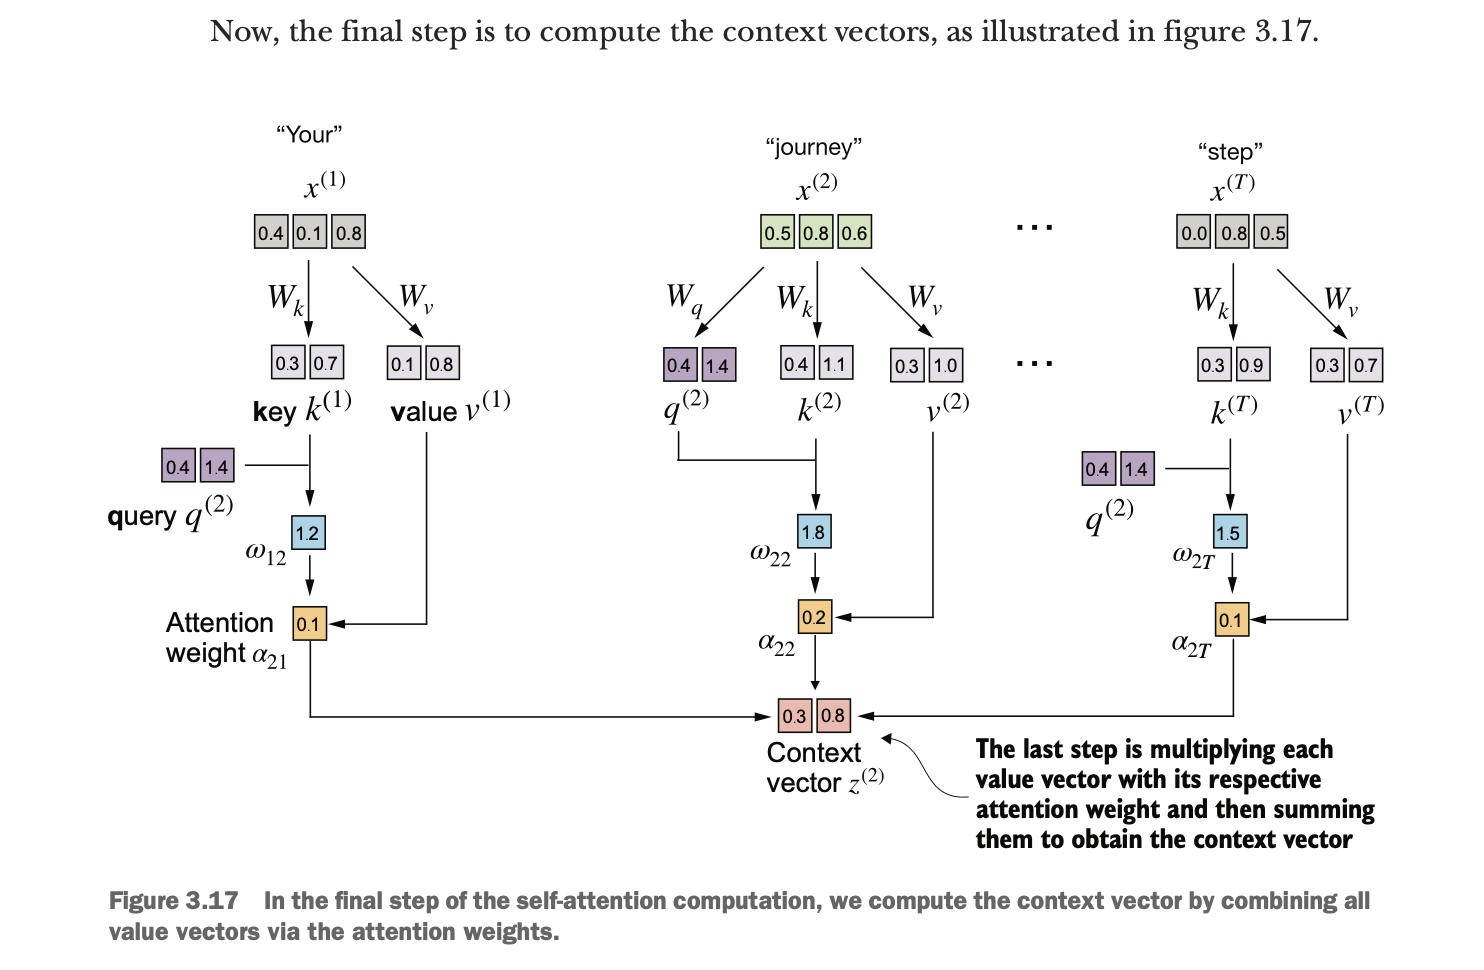


In [76]:
context_vec_2 = attn_weights_2 @ values
print(context_vec_2)

tensor([0.3061, 0.8210])


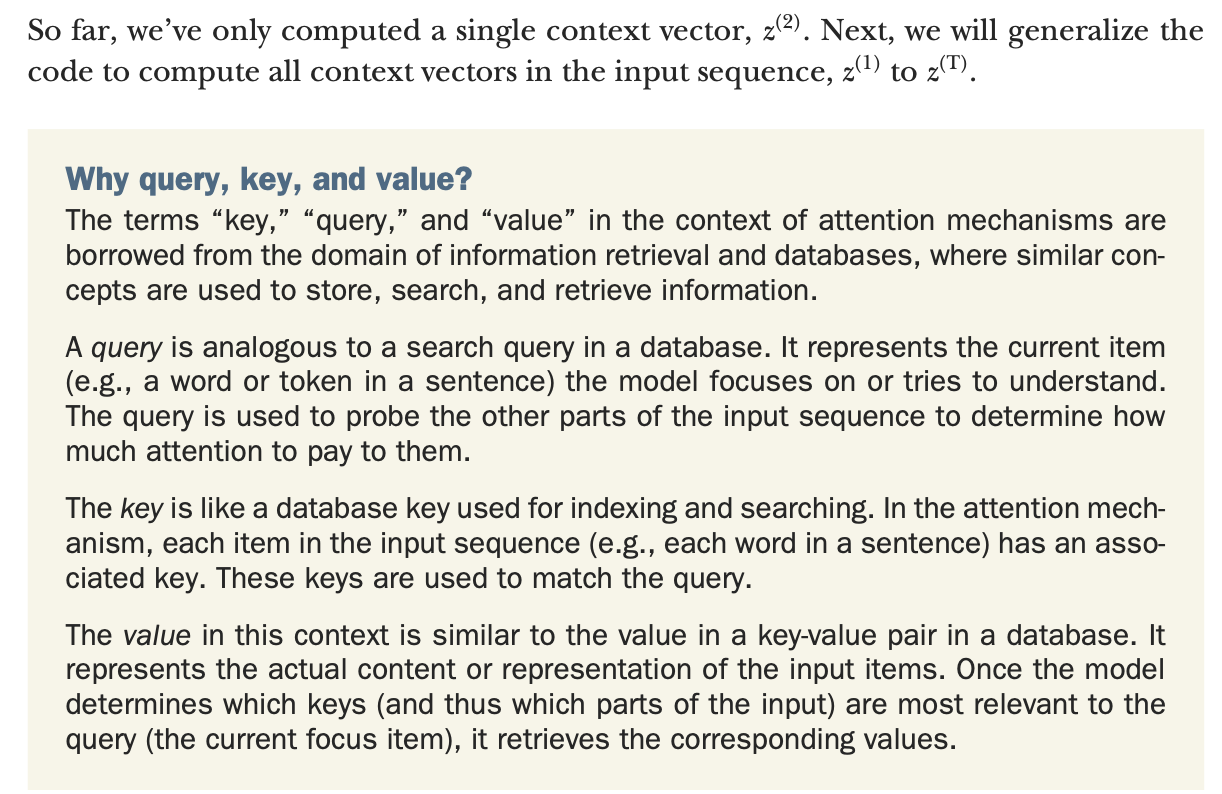


# 3.4.2 Implementing a compact self-attention Python class
